# CMIP6: wet land area contraction vs. land precipitation change, 30–60°N

Across-model test (15 models, first member) of whether the models whose wet land area (daily precipitation > 1 mm) contracts most also lose the most land precipitation (May–Oct).

- **Version 1:** x = slope of wet land % against raw annual land temperature, 2021–2049 (percentage points per °C), from `cmip6_ens_land_daily_temp_histo_fut.ipynb`.
- **Version 2:** x = change in mean wet land % between 2021–2034 and 2035–2049 (percentage points), from the same `precip_cover` files. This is a per-period change like the precipitation change, without dividing by warming.
- **y (both):** relative change in May–Oct land precipitation, 2035–2049 vs 2021–2034 (%), from `precip_total_NH_future_CMIP6.ipynb`.
- **Tests:** Pearson r and Spearman ρ with p-values, leave-one-out r, and a scatter plot. With n = 15, |r| ≥ 0.51 is needed for p < 0.05.
- **Warming check:** models that warm more could show larger changes in both quantities. The land warming of each model (2035–2049 minus 2021–2034) is computed, its correlation with x and y is shown, and the partial correlation of x and y with warming removed is given.

In [1]:
import os
import re

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings(action='ignore')


In [2]:
# ── settings ─────────────────────────────────────────────────────────────────
PC_DIR       = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/CMIP6'     # precip_cover_<model>_ssp370_<member>_30-60N.nc
TAS_DIR      = '/net/atmos/data/cmip6-ng/tas/ann/native'
SFTLF_DIR    = '/net/atmos/data/cmip6-ng/sftlf/fx/native'
SLOPE_CSV    = '/home/jwille/images/global_paper/mid_lat_land_cmip6_precip_coverage_daily_1_temp_regression.csv'   # version 1 x
PRECIP_CSV   = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/NH/cmip6_precip_diff_30-60N.csv'                # y
THRESHOLD    = 1.0                       # mm/day
PERIOD_HIST, PERIOD_FUT = (2021, 2034), (2035, 2049)
latitude     = [30, 60]
FALLBACK_MASK_MODEL = 'MPI-ESM1-2-HR'    # mask for models without an sftlf file (BCC-CSM2-MR)

OUT_FIG = '/home/jwille/images/global_paper/mid_lat_land_cmip6_contraction_vs_precip_change.pdf'
OUT_CSV = '/home/jwille/images/global_paper/mid_lat_land_cmip6_contraction_vs_precip_change.csv'


In [3]:
def member_sort_key(member):
    return [int(n) for n in re.findall(r'\d+', member)]


def nearest_regrid(src, lat, lon):
    ilat = np.abs(src.lat.values[:, None] - np.asarray(lat)[None, :]).argmin(axis=0)
    dlon = (src.lon.values[:, None] - np.asarray(lon)[None, :] + 180) % 360 - 180
    ilon = np.abs(dlon).argmin(axis=0)
    return src.values[np.ix_(ilat, ilon)]


def find_sftlf(model):
    pat = re.compile(rf'^sftlf_fx_{re.escape(model)}_(?P<exp>[^_]+)_(?P<mem>[^_]+)_[^_]+\.nc$')
    cands = [(m['exp'] != 'historical', member_sort_key(m['mem']), f)
             for f in os.listdir(SFTLF_DIR) if (m := pat.match(f))]
    return os.path.join(SFTLF_DIR, sorted(cands)[0][2]) if cands else None


def land_mean_tas(model, member):
    """Annual tas, cos(lat)-weighted mean over land (sftlf > 0) at 30-60N, Series by year."""
    pat = re.compile(rf'^tas_ann_{re.escape(model)}_ssp370_{re.escape(member)}_[^_]+\.nc$')
    f = [f for f in os.listdir(TAS_DIR) if pat.match(f)]
    if not f:
        return None
    tas = xr.open_dataset(os.path.join(TAS_DIR, f[0]))['tas'].load()
    tas = tas.assign_coords(time=tas.time.dt.year).rename(time='year')
    tas = tas.isel(lat=np.where((tas.lat.values >= latitude[0]) & (tas.lat.values <= latitude[1]))[0])
    src = xr.open_dataset(find_sftlf(model) or find_sftlf(FALLBACK_MASK_MODEL))['sftlf'].load()
    land = nearest_regrid(src, tas.lat.values, tas.lon.values) > 0
    w = np.cos(np.deg2rad(tas.lat.values))[:, None] * np.ones(tas.sizes['lon'])
    return pd.Series([np.average(tas.sel(year=y).values[land], weights=w[land]) for y in tas.year.values],
                     index=tas.year.values.astype(int))


def period_mean(s, p):
    return s[(s.index >= p[0]) & (s.index <= p[1])].mean()


In [4]:
# ── per model: wet land % change, land warming (version 2 and warming check) ──
pc_pat = re.compile(r'^precip_cover_(?P<model>[^_]+)_ssp370_(?P<member>r\d+i\d+p\d+f\d+)_30-60N\.nc$')
members = {}
for f in os.listdir(PC_DIR):
    if m := pc_pat.match(f):
        members.setdefault(m['model'], []).append(m['member'])
members = {mod: sorted(mems, key=member_sort_key)[0] for mod, mems in members.items()}

rows = []
for model, member in sorted(members.items(), key=lambda kv: kv[0].lower()):
    da = xr.open_dataset(os.path.join(PC_DIR, f'precip_cover_{model}_ssp370_{member}_30-60N.nc'), use_cftime=True)['wet_land_pct']
    da = da.sel(threshold=THRESHOLD, method='nearest')
    s = pd.Series(da.values, index=da.time.dt.year.values).dropna()
    tas = land_mean_tas(model, member)
    rows.append(dict(model=model, member=member,
                     wet_hist_pct=period_mean(s, PERIOD_HIST), wet_fut_pct=period_mean(s, PERIOD_FUT),
                     dwet_pp=period_mean(s, PERIOD_FUT) - period_mean(s, PERIOD_HIST),
                     dT=(period_mean(tas, PERIOD_FUT) - period_mean(tas, PERIOD_HIST)) if tas is not None else np.nan))
data = pd.DataFrame(rows).set_index('model')

# version 1 x: slope of wet land % vs temperature; y: land precipitation change
slope = pd.read_csv(SLOPE_CSV, index_col=0)
precip = pd.read_csv(PRECIP_CSV, index_col=0)
precip = precip[precip['member'].notna()]                    # model rows only (no summary rows)
data['slope_pp_per_K'] = slope['slope']
data['dpr_land_pct'] = precip['land_diff_pct']
for name, other in [('slope table', slope), ('precip table', precip)]:
    if 'member' in other:
        bad = [m for m in data.index if m in other.index and other.loc[m, 'member'] != data.loc[m, 'member']]
        if bad:
            print(f'WARNING: different members in the {name}: {bad}')
missing = data.index[data[['slope_pp_per_K', 'dpr_land_pct']].isna().any(axis=1)].tolist()
if missing:
    print(f'models missing in the slope or precipitation table, left out: {missing}')
data = data.dropna(subset=['slope_pp_per_K', 'dpr_land_pct', 'dwet_pp'])
data.round(3)


,member,wet_hist_pct,wet_fut_pct,dwet_pp,dT,slope_pp_per_K,dpr_land_pct
model,,,,,,,
ACCESS-ESM1-5,r1i1p1f1,33.602,33.367,-0.235,0.315,-0.618,1.065
BCC-CSM2-MR,r1i1p1f1,30.560,29.951,-0.608,1.111,-0.546,0.345
CAMS-CSM1-0,r2i1p1f1,23.484,23.244,-0.240,0.728,-0.270,-0.788
CanESM5,r1i1p2f1,31.859,31.848,-0.011,0.934,0.212,2.049
CESM2,r1i1p1f1,29.976,29.285,-0.691,0.567,-0.633,-1.475
CNRM-ESM2-1,r1i1p1f2,26.787,26.423,-0.364,0.401,-0.884,-0.407
EC-Earth3,r1i1p1f1,30.028,30.313,0.284,0.535,-0.027,3.175
FGOALS-g3,r1i1p1f1,28.830,28.994,0.164,0.517,0.131,1.141
GFDL-ESM4,r1i1p1f1,33.549,32.964,-0.585,0.568,-1.205,-1.072


In [5]:
# ── correlations ─────────────────────────────────────────────────────────────
def correlate(x, y, label):
    pr, sr, lin = stats.pearsonr(x, y), stats.spearmanr(x, y), stats.linregress(x, y)
    loo = [stats.pearsonr(np.delete(x, i), np.delete(y, i))[0] for i in range(len(x))]
    i_min = int(np.argmin(np.abs(loo)))
    print(f'{label}: n = {len(x)}, Pearson r = {pr[0]:.3f} (p = {pr[1]:.4f}), Spearman rho = {sr[0]:.3f} (p = {sr[1]:.4f}), '
          f'fit slope = {lin.slope:.2f}\n   leave-one-out r: {min(loo):.3f} to {max(loo):.3f} '
          f'(weakest without {data.index[i_min]})')
    return dict(r=pr[0], p=pr[1], rho=sr[0], p_rho=sr[1], lin=lin)


def partial_r(x, y, z):
    """Correlation of x and y after removing the linear effect of z from both; p-value with n - 3 dof."""
    rx = x - np.polyval(np.polyfit(z, x, 1), z)
    ry = y - np.polyval(np.polyfit(z, y, 1), z)
    r = np.corrcoef(rx, ry)[0, 1]
    n = len(x)
    t = r * np.sqrt((n - 3) / (1 - r ** 2))
    return r, 2 * stats.t.sf(abs(t), n - 3)


y = data['dpr_land_pct'].values
res = {
    'v1': correlate(data['slope_pp_per_K'].values, y, 'Version 1 (slope pp/°C)'),
    'v2': correlate(data['dwet_pp'].values, y, 'Version 2 (wet land change pp)'),
}

# warming check
ok = data['dT'].notna().values
print(f'\nLand warming 2035-2049 minus 2021-2034: {data["dT"].min():.2f} to {data["dT"].max():.2f} °C')
for col, lab in [('slope_pp_per_K', 'slope'), ('dwet_pp', 'wet land change'), ('dpr_land_pct', 'precip change')]:
    r, p = stats.pearsonr(data['dT'].values[ok], data[col].values[ok])
    print(f'   r(warming, {lab}) = {r:.2f} (p = {p:.3f})')
for key, col in [('v1', 'slope_pp_per_K'), ('v2', 'dwet_pp')]:
    r, p = partial_r(data[col].values[ok], y[ok], data['dT'].values[ok])
    res[key].update(partial=r, p_partial=p)
    print(f'   {key}: partial r (warming removed) = {r:.3f} (p = {p:.4f})')

os.makedirs(os.path.dirname(OUT_CSV), exist_ok=True)
data.to_csv(OUT_CSV)


Version 1 (slope pp/°C): n = 15, Pearson r = 0.764 (p = 0.0009), Spearman rho = 0.839 (p = 0.0001), fit slope = 2.68
   leave-one-out r: 0.700 to 0.802 (weakest without MPI-ESM1-2-HR)
Version 2 (wet land change pp): n = 15, Pearson r = 0.889 (p = 0.0000), Spearman rho = 0.886 (p = 0.0000), fit slope = 3.92
   leave-one-out r: 0.839 to 0.926 (weakest without MPI-ESM1-2-HR)

Land warming 2035-2049 minus 2021-2034: 0.32 to 1.11 °C
   r(warming, slope) = 0.33 (p = 0.232)
   r(warming, wet land change) = -0.02 (p = 0.931)
   r(warming, precip change) = 0.08 (p = 0.781)
   v1: partial r (warming removed) = 0.784 (p = 0.0009)
   v2: partial r (warming removed) = 0.894 (p = 0.0000)


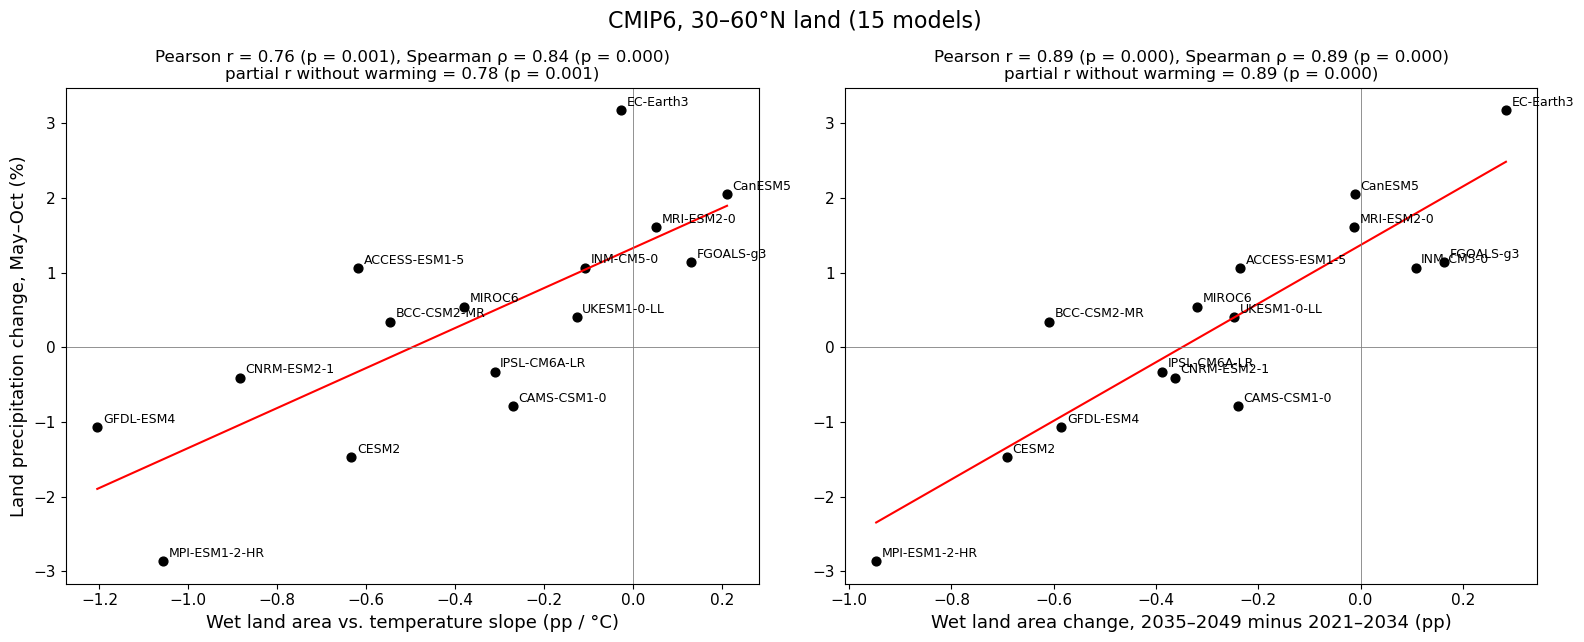

In [6]:
# ── scatter plots ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, key, col, xl in [
        (axes[0], 'v1', 'slope_pp_per_K', 'Wet land area vs. temperature slope (pp / °C)'),
        (axes[1], 'v2', 'dwet_pp', f'Wet land area change, {PERIOD_FUT[0]}–{PERIOD_FUT[1]} minus {PERIOD_HIST[0]}–{PERIOD_HIST[1]} (pp)')]:
    x = data[col].values
    r = res[key]
    ax.scatter(x, y, c='k', s=40)
    for m, xi, yi in zip(data.index, x, y):
        ax.annotate(m, (xi, yi), xytext=(4, 3), textcoords='offset points', fontsize=9)
    xx = np.linspace(x.min(), x.max(), 10)
    ax.plot(xx, r['lin'].intercept + r['lin'].slope * xx, 'r-', lw=1.5)
    ax.axhline(0, c='grey', lw=0.6)
    ax.axvline(0, c='grey', lw=0.6)
    ax.set_xlabel(xl, fontsize=13)
    ax.set_title(f"Pearson r = {r['r']:.2f} (p = {r['p']:.3f}), Spearman ρ = {r['rho']:.2f} (p = {r['p_rho']:.3f})"
                 + (f"\npartial r without warming = {r['partial']:.2f} (p = {r['p_partial']:.3f})" if 'partial' in r else ''),
                 fontsize=12)
    ax.tick_params(labelsize=11)
axes[0].set_ylabel(f'Land precipitation change, May–Oct (%)', fontsize=13)
fig.suptitle(f'CMIP6, 30–60°N land ({len(data)} models)', fontsize=16)
plt.tight_layout()
os.makedirs(os.path.dirname(OUT_FIG), exist_ok=True)
plt.savefig(OUT_FIG, format='pdf', bbox_inches='tight')
plt.show()
